## 1. Imports and dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, LeaveOneOut,
    TimeSeriesSplit, cross_validate, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
DATA_FILE = "Advanced_Regression_HousePrice_Dataset_3800.xlsx"

df = pd.read_excel(DATA_FILE)
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 3800 rows × 12 columns


,property_id,sale_date,area_sqft,bedrooms,bathrooms,location_score,property_age,distance_city_km,near_school,near_metro,crime_rate_index,house_price_inr
0,200001,2014-01-01,2181,6,4,8.1,21,3.8,0,0,4.84,35154898
1,200002,2019-12-01,2383,5,4,5.3,28,10.9,1,1,2.89,26710893
2,200003,2016-10-01,1047,3,3,5.9,7,27.5,0,1,4.04,11216242
3,200004,2013-03-01,1753,4,3,7.0,27,12.1,0,0,3.28,21984310
4,200005,2013-07-01,1728,4,4,10.0,32,1.4,0,1,3.84,25080429


## 2. Initial data checks

In [2]:
print("Column types:")
display(df.dtypes.rename("data_type").to_frame())

print("Missing values by column:")
display(df.isna().sum().rename("missing_count").to_frame())

print(f"Duplicate rows: {df.duplicated().sum()}")
display(df.describe().T)

Column types:


,data_type
property_id,int64
sale_date,datetime64[ns]
area_sqft,int64
bedrooms,int64
bathrooms,int64
location_score,float64
property_age,int64
distance_city_km,float64
near_school,int64
near_metro,int64


Missing values by column:


,missing_count
property_id,0
sale_date,0
area_sqft,0
bedrooms,0
bathrooms,0
location_score,0
property_age,0
distance_city_km,0
near_school,0
near_metro,0


Duplicate rows: 0


,count,mean,min,25%,50%,75%,max,std
property_id,3800.0,201900.5,200001.0,200950.75,201900.5,202850.25,203800.0,1097.10984
sale_date,3800,2016-11-27 23:45:13.263158016,2010-01-01 00:00:00,2013-06-01 00:00:00,2016-12-01 00:00:00,2020-05-01 00:00:00,2023-12-01 00:00:00,NaN
area_sqft,3800.0,1716.925526,500.0,1322.0,1700.5,2105.0,3776.0,582.996559
bedrooms,3800.0,3.428158,1.0,2.0,3.0,4.0,7.0,1.356682
bathrooms,3800.0,2.916316,1.0,2.0,3.0,4.0,6.0,1.13354
location_score,3800.0,6.502237,1.0,5.3,6.5,7.7,10.0,1.766945
property_age,3800.0,22.537105,1.0,14.0,20.0,29.0,80.0,12.32574
distance_city_km,3800.0,13.085132,1.0,8.5,13.0,17.5,38.7,6.537425
near_school,3800.0,0.548421,0.0,0.0,1.0,1.0,1.0,0.497715
near_metro,3800.0,0.472895,0.0,0.0,0.0,1.0,1.0,0.49933


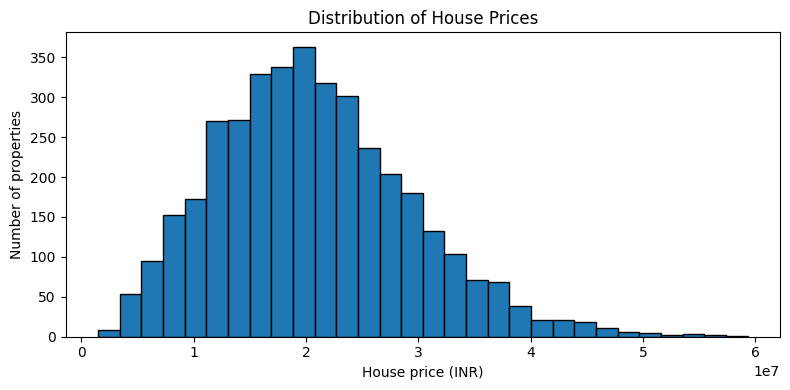

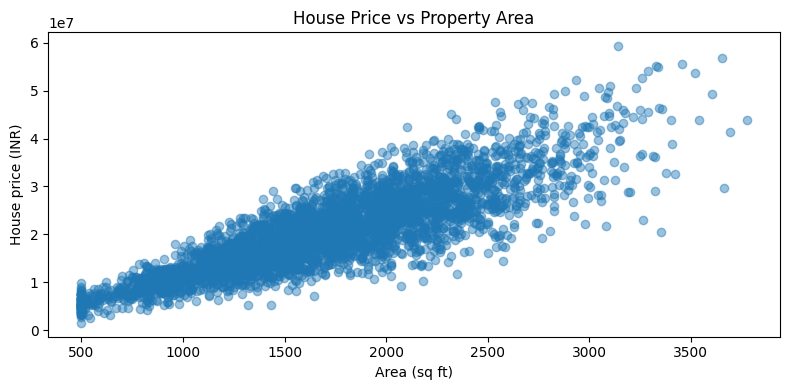

In [3]:
target = "house_price_inr"

plt.figure(figsize=(8, 4))
plt.hist(df[target], bins=30, edgecolor="black")
plt.title("Distribution of House Prices")
plt.xlabel("House price (INR)")
plt.ylabel("Number of properties")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(df["area_sqft"], df[target], alpha=0.45)
plt.title("House Price vs Property Area")
plt.xlabel("Area (sq ft)")
plt.ylabel("House price (INR)")
plt.tight_layout()
plt.show()

**Initial observation:** The dataset contains property characteristics, location indicators, a sale date, and the sale price. `property_id` is an identifier rather than a useful property characteristic, so it is excluded from model features. The sale date is converted into numeric year/month features for ordinary regression models; a chronological split is also used to check time-based generalization.

## 3. Feature preparation and train/test split

In [4]:
data = df.copy()
data["sale_year"] = data["sale_date"].dt.year
data["sale_month"] = data["sale_date"].dt.month
data = data.drop(columns=["property_id", "sale_date"])

X = data.drop(columns=[target])
y = data[target]

numeric_features = X.columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features)
    ],
    remainder="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Feature columns:", X.columns.tolist())
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")

Feature columns: ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'property_age', 'distance_city_km', 'near_school', 'near_metro', 'crime_rate_index', 'sale_year', 'sale_month']
Training rows: 3040 | Test rows: 760


## 4. Regularized linear models: Ridge and Lasso

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alpha_grid = {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]}

ridge_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", Ridge())
])
lasso_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", Lasso(max_iter=20000))
])

ridge_search = GridSearchCV(ridge_pipe, alpha_grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_search = GridSearchCV(lasso_pipe, alpha_grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best Ridge CV RMSE:", round(-ridge_search.best_score_, 2))
print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])
print("Best Lasso CV RMSE:", round(-lasso_search.best_score_, 2))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best Ridge alpha: 1.0
Best Ridge CV RMSE: 2495255.21
Best Lasso alpha: 100.0
Best Lasso CV RMSE: 2495268.72


In [6]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

linear_results = []
for name, search in [("Ridge", ridge_search), ("Lasso", lasso_search)]:
    pred = search.predict(X_test)
    linear_results.append({"Model": name, **regression_metrics(y_test, pred)})

linear_results = pd.DataFrame(linear_results).sort_values("RMSE")
display(linear_results.round(3))

,Model,MAE,MSE,RMSE,R2
1,Lasso,1945525.482,6.450219e+12,2539728.190,0.92
0,Ridge,1945385.398,6.451358e+12,2539952.397,0.92


In [7]:
best_ridge = ridge_search.best_estimator_
best_lasso = lasso_search.best_estimator_

feature_names = X.columns
ridge_coef = pd.Series(best_ridge.named_steps["model"].coef_, index=feature_names)
lasso_coef = pd.Series(best_lasso.named_steps["model"].coef_, index=feature_names)

coef_table = pd.DataFrame({
    "Ridge coefficient": ridge_coef,
    "Lasso coefficient": lasso_coef
})
display(coef_table.round(2))
print("Lasso coefficients set to zero:", int((lasso_coef == 0).sum()))

,Ridge coefficient,Lasso coefficient
area_sqft,6948656.09,6955960.42
bedrooms,295295.76,289124.90
bathrooms,273072.99,273106.57
location_score,3678704.84,3680757.84
property_age,-649942.47,-650031.72
distance_city_km,-28521.05,-27082.65
near_school,15720.28,15549.59
near_metro,52546.42,52535.55
crime_rate_index,-140692.15,-140530.34
sale_year,300962.15,301051.55


Lasso coefficients set to zero: 0


## 5. Cross-validation strategies

In [8]:
def rmse_scorer(estimator, X_part, y_part):
    return -np.sqrt(mean_squared_error(y_part, estimator.predict(X_part)))

# Keep the target bins balanced across folds for the stratified regression variant.
y_bins = pd.qcut(y_train, q=5, labels=False, duplicates="drop")
strat_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for label, splitter, use_bins in [
    ("K-Fold", cv, False),
    ("Stratified K-Fold (binned target)", strat_cv, True)
]:
    cv_splits = list(splitter.split(X_train, y_bins)) if use_bins else splitter
    scores = cross_validate(
        best_ridge, X_train, y_train, cv=cv_splits,
        scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"},
        n_jobs=-1
    )
    cv_rows.append({
        "Strategy": label,
        "Mean RMSE": -scores["test_rmse"].mean(),
        "RMSE SD": scores["test_rmse"].std(),
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean R2": scores["test_r2"].mean()
    })

display(pd.DataFrame(cv_rows).round(3))

,Strategy,Mean RMSE,RMSE SD,Mean MAE,Mean R2
0,K-Fold,2495255.213,88893.461,1907184.824,0.916
1,Stratified K-Fold (binned target),2490950.155,78045.835,1904545.053,0.917


In [9]:
# LOOCV on a fixed subset to demonstrate the method without a very long run.
small_n = min(250, len(X_train))
X_small = X_train.iloc[:small_n]
y_small = y_train.iloc[:small_n]
loo_scores = cross_validate(
    best_ridge, X_small, y_small, cv=LeaveOneOut(),
    scoring={"rmse": "neg_root_mean_squared_error"},
    n_jobs=-1
)
print(f"LOOCV demonstration subset: {small_n} training rows")
print(f"Mean LOOCV RMSE: {-loo_scores['test_rmse'].mean():,.2f}")

LOOCV demonstration subset: 250 training rows
Mean LOOCV RMSE: 1,829,083.77


In [10]:
# Chronological split: earlier sales are used to predict later sales.
ordered = data.sort_values("sale_year" if "sale_year" in data.columns else "sale_date")
X_time = ordered.drop(columns=[target])
y_time = ordered[target]
time_cv = TimeSeriesSplit(n_splits=5)

time_scores = cross_validate(
    best_ridge, X_time, y_time, cv=time_cv,
    scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"},
    n_jobs=-1
)
print("Time Series Split results (chronological folds):")
print(f"Mean RMSE: {-time_scores['test_rmse'].mean():,.2f}")
print(f"Mean MAE: {-time_scores['test_mae'].mean():,.2f}")
print(f"Mean R²: {time_scores['test_r2'].mean():.3f}")

Time Series Split results (chronological folds):
Mean RMSE: 2,505,002.75
Mean MAE: 1,913,751.61
Mean R²: 0.917


## 6. Tree-based regression models

In [11]:
tree_models = {
    "Decision Tree": Pipeline([
        ("prep", preprocessor),
        ("model", DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=8, min_samples_leaf=5))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=120, max_depth=None, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

tree_results = []
for name, model in tree_models.items():
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    train_metrics = regression_metrics(y_train, train_pred)
    test_metrics = regression_metrics(y_test, test_pred)
    tree_results.append({
        "Model": name,
        "Train RMSE": train_metrics["RMSE"],
        "Test RMSE": test_metrics["RMSE"],
        "Test MAE": test_metrics["MAE"],
        "Test R2": test_metrics["R2"]
    })

display(pd.DataFrame(tree_results).sort_values("Test RMSE").round(3))

,Model,Train RMSE,Test RMSE,Test MAE,Test R2
1,Random Forest,1072289.139,2391788.859,1745940.655,0.929
0,Decision Tree,1983854.066,2815955.064,2065207.329,0.902


## 7. Support Vector Regression (SVR)

In [12]:
svr_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", SVR())
])
svr_grid = [
    {"model__kernel": ["linear"], "model__C": [0.1, 1, 10], "model__epsilon": [0.1, 0.2]},
    {"model__kernel": ["rbf"], "model__C": [1, 10], "model__epsilon": [0.1, 0.2], "model__gamma": ["scale"]}
]
svr_search = GridSearchCV(
    svr_pipe, svr_grid, cv=3, scoring="neg_root_mean_squared_error",
    n_jobs=-1, verbose=0
)
svr_search.fit(X_train, y_train)
print("Best SVR settings:", svr_search.best_params_)
print(f"Best SVR CV RMSE: {-svr_search.best_score_:,.2f}")

Best SVR settings: {'model__C': 10, 'model__epsilon': 0.1, 'model__kernel': 'linear'}
Best SVR CV RMSE: 8,636,004.28


## 8. Model comparison on the held-out test set

In [13]:
all_models = {
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "Decision Tree": tree_models["Decision Tree"],
    "Random Forest": tree_models["Random Forest"],
    "SVR": svr_search.best_estimator_
}

comparison_rows = []
for name, model in all_models.items():
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    train_m = regression_metrics(y_train, train_prediction)
    test_m = regression_metrics(y_test, test_prediction)
    comparison_rows.append({
        "Model": name,
        "Train RMSE": train_m["RMSE"],
        "Test RMSE": test_m["RMSE"],
        "Test MAE": test_m["MAE"],
        "Test MSE": test_m["MSE"],
        "Test R2": test_m["R2"],
        "Train-Test RMSE Gap": test_m["RMSE"] - train_m["RMSE"]
    })

comparison = pd.DataFrame(comparison_rows).sort_values("Test RMSE").reset_index(drop=True)
display(comparison.round(3))

,Model,Train RMSE,Test RMSE,Test MAE,Test MSE,Test R2,Train-Test RMSE Gap
0,Random Forest,1072289.139,2391788.859,1745940.655,5.720654e+12,0.929,1319499.719
1,Lasso,2482394.798,2539728.190,1945525.482,6.450219e+12,0.920,57333.392
2,Ridge,2482398.578,2539952.397,1945385.398,6.451358e+12,0.920,57553.818
3,Decision Tree,1983854.066,2815955.064,2065207.329,7.929603e+12,0.902,832100.997
4,SVR,8619762.706,8939711.446,6956494.980,7.991844e+13,0.008,319948.740


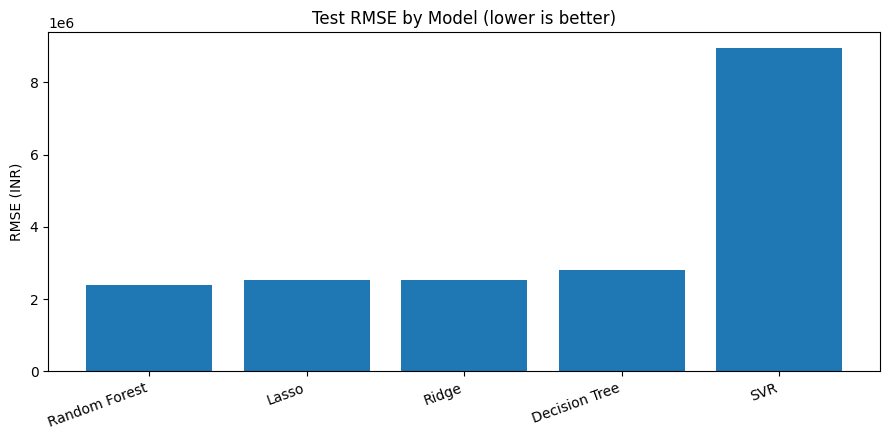

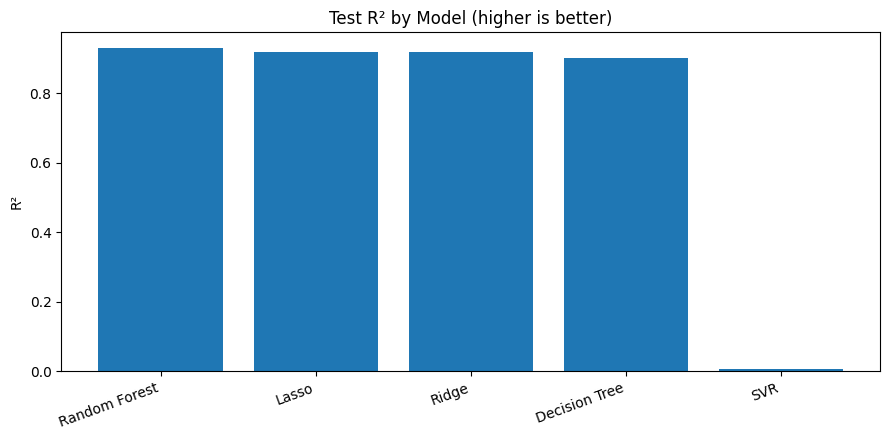

In [14]:
plt.figure(figsize=(9, 4.5))
plt.bar(comparison["Model"], comparison["Test RMSE"])
plt.title("Test RMSE by Model (lower is better)")
plt.ylabel("RMSE (INR)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
plt.bar(comparison["Model"], comparison["Test R2"])
plt.title("Test R² by Model (higher is better)")
plt.ylabel("R²")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 9. Residual analysis for the selected model

Best model by test RMSE: Random Forest
Test RMSE: 2,391,788.86 INR
Test MAE: 1,745,940.65 INR
Test R²: 0.929


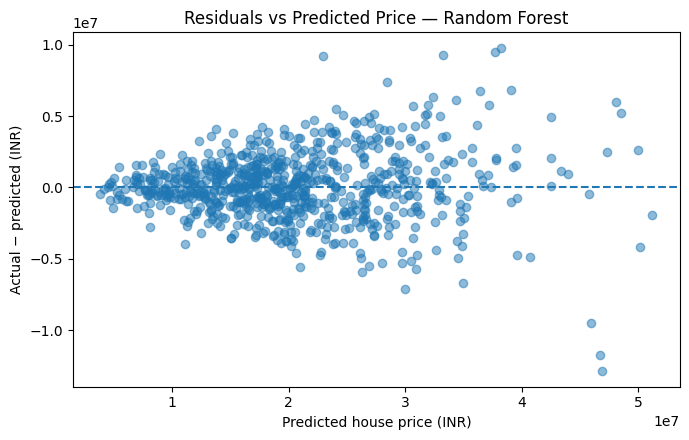

In [15]:
best_model_name = comparison.iloc[0]["Model"]
best_model = all_models[best_model_name]
test_predictions = best_model.predict(X_test)
residuals = y_test - test_predictions

print("Best model by test RMSE:", best_model_name)
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, test_predictions)):,.2f} INR")
print(f"Test MAE: {mean_absolute_error(y_test, test_predictions):,.2f} INR")
print(f"Test R²: {r2_score(y_test, test_predictions):.3f}")

plt.figure(figsize=(7, 4.5))
plt.scatter(test_predictions, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.title(f"Residuals vs Predicted Price — {best_model_name}")
plt.xlabel("Predicted house price (INR)")
plt.ylabel("Actual − predicted (INR)")
plt.tight_layout()
plt.show()

## 10. Conclusions

In [16]:
best_row = comparison.iloc[0]
largest_gap_row = comparison.loc[comparison["Train-Test RMSE Gap"].idxmax()]

print(f"1. Lowest test RMSE: {best_row['Model']} ({best_row['Test RMSE']:,.2f} INR).")
print(f"2. Its test MAE is {best_row['Test MAE']:,.2f} INR and test R² is {best_row['Test R2']:.3f}.")
print(f"3. Largest train-to-test RMSE gap: {largest_gap_row['Model']} "
      f"({largest_gap_row['Train-Test RMSE Gap']:,.2f} INR).")
print("4. Regularization controls coefficient size and can improve generalization.")
print("5. Cross-validation gives a more stable estimate than relying on one split alone.")
print("6. The preferred model should be chosen using validation results, then reported once on the held-out test set.")

1. Lowest test RMSE: Random Forest (2,391,788.86 INR).
2. Its test MAE is 1,745,940.65 INR and test R² is 0.929.
3. Largest train-to-test RMSE gap: Random Forest (1,319,499.72 INR).
4. Regularization controls coefficient size and can improve generalization.
5. Cross-validation gives a more stable estimate than relying on one split alone.
6. The preferred model should be chosen using validation results, then reported once on the held-out test set.
